# ASL Sign Language Recognition Research

This notebook demonstrates the process of loading the functionality of the ASL project for research purposes. It covers:
1.  Data Loading and Preprocessing
2.  Data Visualization
3.  Model Training (KNN)
4.  Evaluation and Metrics

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

%matplotlib inline

In [2]:
# --- Feature Extraction & Preprocessing Modules ---

def get_gabor_kernels():
    kernels = []
    # 4 scales given by sigma, 4 orientations given by theta
    for theta in np.arange(0, np.pi, np.pi / 4):
        for sigma in [1, 3, 5, 7]: 
            lam = np.pi / 4
            gamma = 0.5
            psi = 0
            ksize = 15 # Kernel size
            kernel = cv2.getGaborKernel((ksize, ksize), sigma, theta, lam, gamma, psi, ktype=cv2.CV_32F)
            kernels.append(kernel)
    return kernels

# Pre-calculate Gabor kernels once
GABOR_KERNELS = get_gabor_kernels()

def extract_hocd_features(binary_mask, bins=32):
    """
    Histogram of Centroid Distances (HOCD)
    Expects a binary mask of the hand.
    """
    if binary_mask is None:
        return np.zeros(bins)

    # 1. Calculate Centroid
    M = cv2.moments(binary_mask)
    if M["m00"] == 0:
        return np.zeros(bins)
    cX = int(M["m10"] / M["m00"])
    cY = int(M["m01"] / M["m00"])
    
    # 2. Find Contours (Boundaries)
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return np.zeros(bins)
    
    # Assume largest contour is the hand boundary
    cnt = max(contours, key=cv2.contourArea)
    
    # 3. Calculate Euclidean Distance from Centroid to each boundary point
    dists = []
    for point in cnt:
        px, py = point[0]
        # Euclidean distance
        d = np.sqrt((px - cX)**2 + (py - cY)**2)
        dists.append(d)
    
    dists = np.array(dists)
    
    # 4. Normalize Distances and create Histogram
    if len(dists) > 0 and dists.max() > 0:
        dists = dists / dists.max()
        
    hist, _ = np.histogram(dists, bins=bins, range=(0, 1))
    
    # Normalize histogram to sum to 1
    hist = hist.astype("float")
    if hist.sum() > 0:
        hist /= hist.sum()
        
    return hist

def extract_gabor_features(gray_img, size=(64, 64)):
    """
    Gabor Filter Bank features for texture.
    """
    if gray_img is None:
        # Return zeros matching Gabor output size (Kernels * 2 stats)
        return np.zeros(len(GABOR_KERNELS) * 2)

    # Resize to fixed size
    img_resized = cv2.resize(gray_img, size)
    
    feats = []
    for kernel in GABOR_KERNELS:
        # Apply filter
        fimg = cv2.filter2D(img_resized, cv2.CV_8UC3, kernel)
        
        # Local Averaging (Using mean and variance as summary stats)
        feats.append(fimg.mean())
        feats.append(fimg.var())
        
    return np.array(feats)

def preprocess_image(img_bgr):
    """
    Applies Grayscale, Thresholding, Cleaning, and ROI extraction.
    Returns: (cropped_binary_mask, cropped_grayscale_img)
    """
    if img_bgr is None:
        return None, None

    # 1. Grayscale
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # 2. Blur & Threshold (Otsu)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    # 3. Cleaning (Hole Filling & Dilation)
    # Dilation to reduce noise
    kernel = np.ones((3, 3), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)
    
    # Closing to fill holes inside the hand
    # Fixed: Removed dependency on undefined variable 'self_defined_iters'
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2) 
    
    # 4. Region Selection (Get Largest Contour)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return None, None
        
    # Get largest contour (Hand)
    c = max(contours, key=cv2.contourArea)
    if cv2.contourArea(c) < 500: # Ignore small noise
        return None, None
        
    # 5. Bounding Box & Crop
    x, y, w, h = cv2.boundingRect(c)
    
    # Add small padding
    pad = 10
    h_img, w_img = gray.shape
    x1 = max(0, x - pad)
    y1 = max(0, y - pad)
    x2 = min(w_img, x + w + pad)
    y2 = min(h_img, y + h + pad)
    
    # Ensure valid crop coordinates
    if x2 <= x1 or y2 <= y1:
        return None, None

    # Crop
    crop_mask = thresh[y1:y2, x1:x2]
    crop_gray = gray[y1:y2, x1:x2]
    
    return crop_mask, crop_gray

def get_augmentations(img_bgr):
    """
    Returns a list of (name, image) tuples including Original and various augmentations.
    """
    augs = []
    
    # 1. Original
    augs.append(("Original", img_bgr))
    
    rows, cols, _ = img_bgr.shape
    
    # --- Geometric ---
    # 2. Rotation
    M_rot = cv2.getRotationMatrix2D((cols/2, rows/2), 15, 1) # 15 degrees
    img_rot = cv2.warpAffine(img_bgr, M_rot, (cols, rows), borderMode=cv2.BORDER_REPLICATE)
    augs.append(("Geo_Rotation", img_rot))
    
    # 3. Flip
    img_flip = cv2.flip(img_bgr, 1) # Horizontal
    augs.append(("Geo_Flip", img_flip))
    
    # 4. Shear
    pts1 = np.float32([[10, 10], [cols-10, 10], [10, rows-10]])
    pts2 = np.float32([[5, 20], [cols-20, 10], [25, rows-20]])
    M_shear = cv2.getAffineTransform(pts1, pts2)
    img_shear = cv2.warpAffine(img_bgr, M_shear, (cols, rows), borderMode=cv2.BORDER_REPLICATE)
    augs.append(("Geo_Shear", img_shear))
    
    # --- Color Space ---
    # 5. Brightness
    # Increase brightness
    img_bright = cv2.convertScaleAbs(img_bgr, alpha=1.2, beta=30)
    augs.append(("Color_Brightness", img_bright))
    
    # 6. Contrast
    img_contrast = cv2.convertScaleAbs(img_bgr, alpha=1.5, beta=0)
    augs.append(("Color_Contrast", img_contrast))

    # --- Kernel ---
    # 7. Blur (Gaussian)
    img_blur = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    augs.append(("Kernel_Blur", img_blur))
    
    # 8. Sharpen
    kernel_sharp = np.array([[0, -1, 0],
                             [-1, 5,-1],
                             [0, -1, 0]])
    img_sharp = cv2.filter2D(img_bgr, -1, kernel_sharp)
    augs.append(("Kernel_Sharpen", img_sharp))
    
    return augs

def load_dataset(dataset_path):
    print(f"Loading dataset from: {dataset_path}")
    X = []
    y = []
    
    if not os.path.exists(dataset_path):
        print("Dataset directory not found.")
        return np.array([]), np.array([])
    
    count = Counter()
    limit_per_class = 50 # Reduced limit because augmentation multiplies data by 8x
    
    valid_folders = [f for f in os.listdir(dataset_path) if f.endswith('-samples')]
    print(f"Found {len(valid_folders)} class folders.")
    
    for folder_name in sorted(valid_folders):
        folder_path = os.path.join(dataset_path, folder_name)
        label = folder_name.split('-')[0].lower()
        
        files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        class_samples_loaded = 0
        
        for filename in files:
            if count[label] >= limit_per_class:
                break
                
            img_path = os.path.join(folder_path, filename)
            try:
                img = cv2.imread(img_path)
                if img is None: continue
                
                # Apply Augmentations FIRST
                augmented_set = get_augmentations(img)
                
                for aug_name, aug_img in augmented_set:
                    # Apply Preprocessing Pipeline
                    crop_mask, crop_gray = preprocess_image(aug_img)
                    
                    if crop_mask is None or crop_gray is None:
                        continue
                        
                    # Extract Features
                    # A. HOCD from Binary Mask
                    hocd = extract_hocd_features(crop_mask)
                    
                    # B. Gabor from Grayscale
                    gabor = extract_gabor_features(crop_gray)
                    
                    # C. Fusion
                    features = np.concatenate([hocd, gabor])
                    
                    X.append(features)
                    y.append(label)
                
                count[label] += 1 # Count original image processed
                
            except Exception as e:
                # print(f"Error processing {filename}: {e}")
                continue
                
    print("Class distribution (original images processed):", dict(count))
    print(f"Total feature vectors extracted (with augmentation): {len(X)}")
    if len(X) > 0:
        print(f"Feature vector length: {len(X[0])}")
    return np.array(X), np.array(y)

### Load Data
We load the images from the `MasseyDataset` folder.

In [3]:
dataset_dir = "dataset"
X, y = load_dataset(dataset_dir)

if len(X) > 0:
    print(f"X shape: {X.shape}, y shape: {y.shape}")
else:
    print("No data loaded. Check dataset path.")

Loading dataset from: dataset
Found 24 class folders.
Class distribution (original images processed): {'a': 50, 'b': 50, 'c': 50, 'd': 50, 'e': 50, 'f': 50, 'g': 50, 'h': 50, 'i': 50, 'k': 50, 'l': 50, 'm': 50, 'n': 50, 'o': 50, 'p': 50, 'q': 50, 'r': 50, 's': 50, 't': 50, 'u': 50, 'v': 50, 'w': 50, 'x': 50, 'y': 50}
Total feature vectors extracted (with augmentation): 9600
Feature vector length: 64
X shape: (9600, 64), y shape: (9600,)


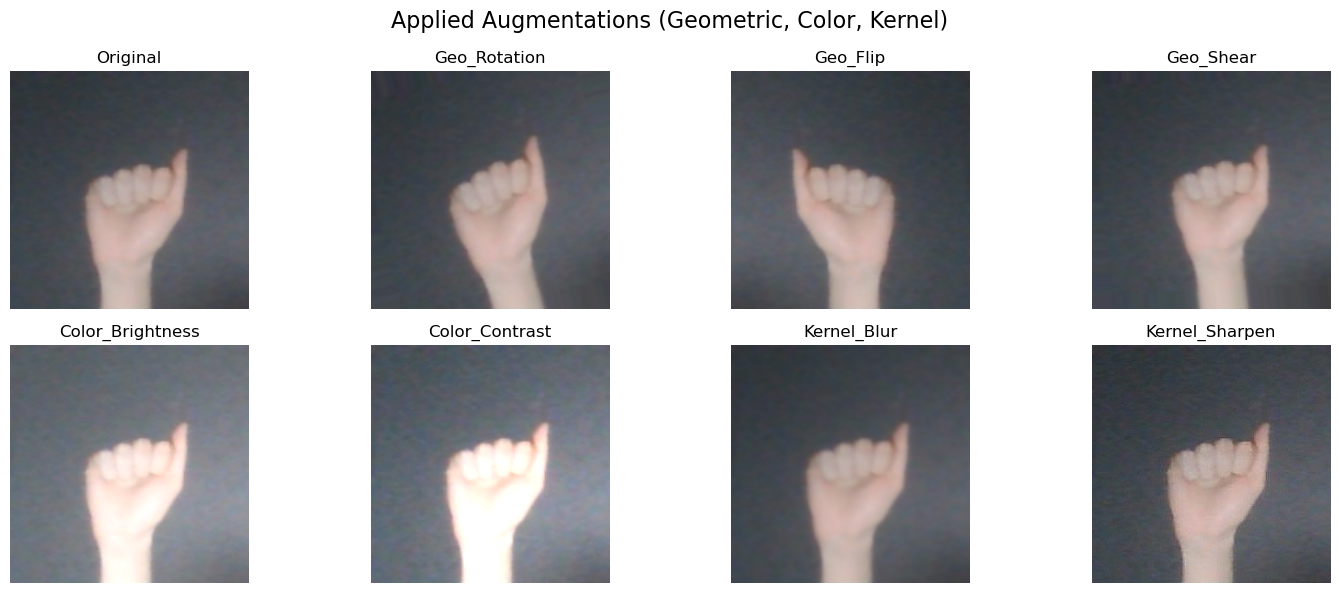


Visualizing Preprocessing pipeline on 'Original' image...


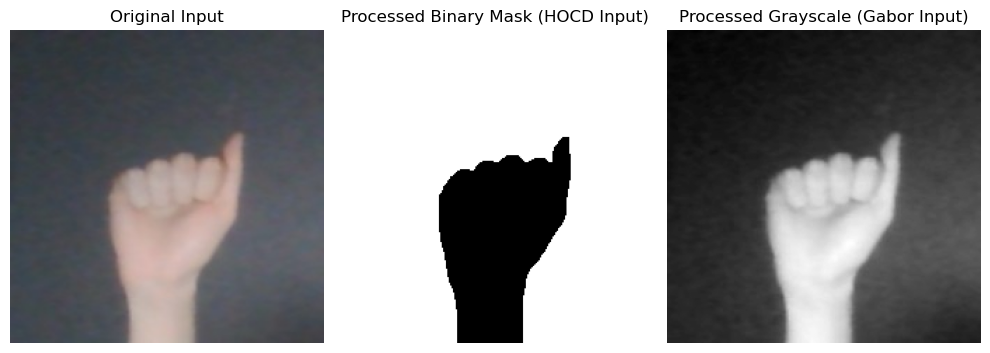

Feature Vector Shapes -> HOCD: (32,), Gabor: (32,), Fused: (64,)


In [4]:
# Visualization of Augmentations and Preprocessing
def visualize_pipeline(dataset_path):
    # Find a sample image
    sample_img_path = None
    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                sample_img_path = os.path.join(root, file)
                break
        if sample_img_path:
            break
            
    if not sample_img_path:
        print("No image found for visualization.")
        return

    # Load
    img = cv2.imread(sample_img_path)
    
    # Get augmentations
    augs = get_augmentations(img)
    
    # Plot Augmentations
    plt.figure(figsize=(15, 6))
    plt.suptitle("Applied Augmentations (Geometric, Color, Kernel)", fontsize=16)
    
    for i, (name, aug_img) in enumerate(augs):
        plt.subplot(2, 4, i+1)
        plt.imshow(cv2.cvtColor(aug_img, cv2.COLOR_BGR2RGB))
        plt.title(name)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Visualize Preprocessing Steps on Original
    print("\nVisualizing Preprocessing pipeline on 'Original' image...")
    crop_mask, crop_gray = preprocess_image(img)
    
    if crop_mask is not None:
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 3, 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title("Original Input")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(crop_mask, cmap='gray')
        plt.title("Processed Binary Mask (HOCD Input)")
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(crop_gray, cmap='gray')
        plt.title("Processed Grayscale (Gabor Input)")
        plt.axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Show Feature Vector shape
        hocd = extract_hocd_features(crop_mask)
        gabor = extract_gabor_features(crop_gray)
        fusion = np.concatenate([hocd, gabor])
        print(f"Feature Vector Shapes -> HOCD: {hocd.shape}, Gabor: {gabor.shape}, Fused: {fusion.shape}")

# Run visualization
visualize_pipeline(dataset_dir)

### Visualize Samples
Let's look at some random samples from the dataset to understand what the model sees.

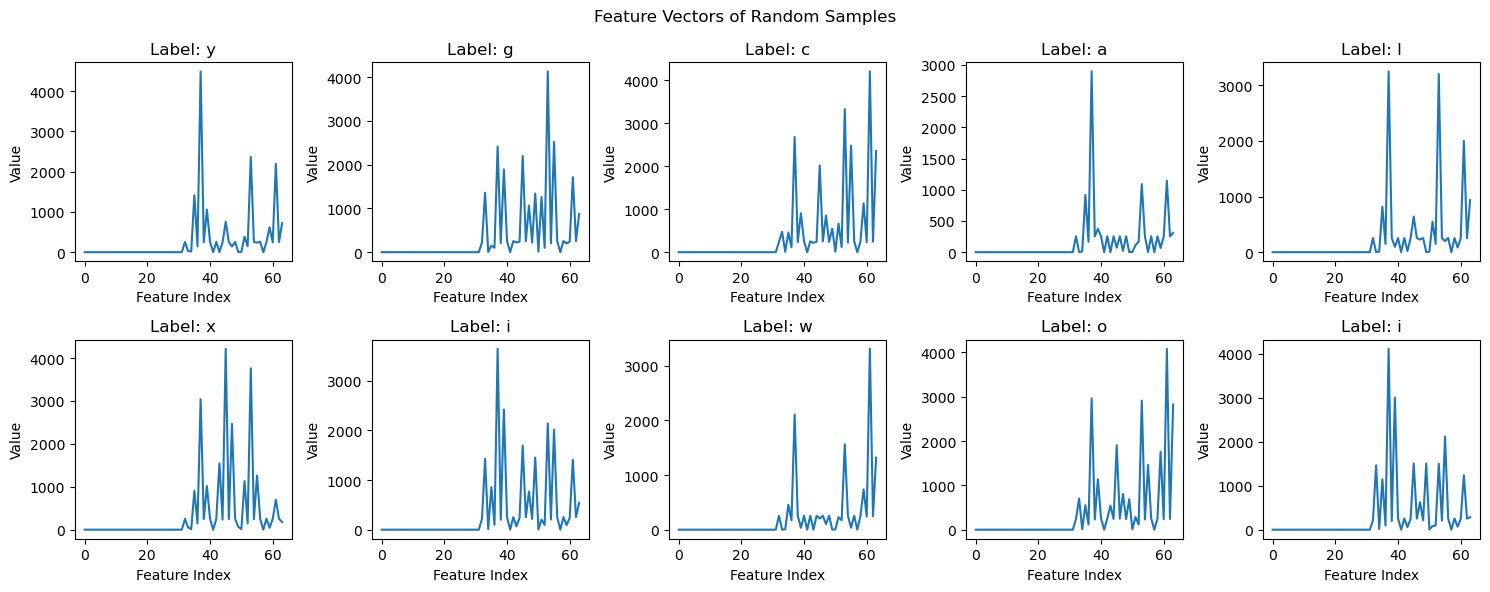

In [5]:
if len(X) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    indices = np.random.choice(len(X), 10, replace=False)
    
    for i, ax in enumerate(axes.flat):
        idx = indices[i]
        
        # NOTE: Current X contains feature vectors (HOCD + Gabor), NOT raw images.
        # We cannot reshape features back to (64,64) image.
        # Instead, we will visualize the feature vector values as a bar plot or line.
        
        feature_vector = X[idx]
        ax.plot(feature_vector)
        ax.set_title(f"Label: {y[idx]}")
        ax.set_xlabel("Feature Index")
        ax.set_ylabel("Value")
        
        # Remove axis ticks for cleaner look if needed
        # ax.axis('off') 
        
    plt.suptitle("Feature Vectors of Random Samples")
    plt.tight_layout()
    plt.show()

### Model Training
We will split the data into 80% training and 20% testing sets. Then we train a K-Nearest Neighbors (KNN) classifier.

In [6]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# Dictionary to store results
model_results = {}

Training set size: 7680
Test set size: 1920


In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import pandas as pd

# 1. K-Nearest Neighbors (KNN)
print("Training KNN...")
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
knn_acc = accuracy_score(y_test, knn.predict(X_test))
model_results['KNN'] = knn_acc
print(f"KNN Accuracy: {knn_acc*100:.2f}%")

# 2. Support Vector Machine (SVM)
print("Training SVM...")
svm = SVC(kernel='linear') # Linear kernel often works well for high dimensional data
svm.fit(X_train, y_train)
svm_acc = accuracy_score(y_test, svm.predict(X_test))
model_results['SVM'] = svm_acc
print(f"SVM Accuracy: {svm_acc*100:.2f}%")

# 3. Random Forest
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))
model_results['Random Forest'] = rf_acc
print(f"Random Forest Accuracy: {rf_acc*100:.2f}%")

# 4. Multi-layer Perceptron (Neural Network)
print("Training MLP (Neural Network)...")
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp.fit(X_train, y_train)
mlp_acc = accuracy_score(y_test, mlp.predict(X_test))
model_results['MLP Neural Net'] = mlp_acc
print(f"MLP Accuracy: {mlp_acc*100:.2f}%")

Training KNN...
KNN Accuracy: 91.09%
Training SVM...


### Model Comparison
We compare the performance of KNN, SVM, Random Forest, and MLP Classifiers.

            Model  Accuracy (%)
2   Random Forest     98.958333
1             SVM     96.666667
0             KNN     87.916667
3  MLP Neural Net      5.347222


C:\Users\Sultan Mahamud Opu\AppData\Local\Temp\ipykernel_14392\602517800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')


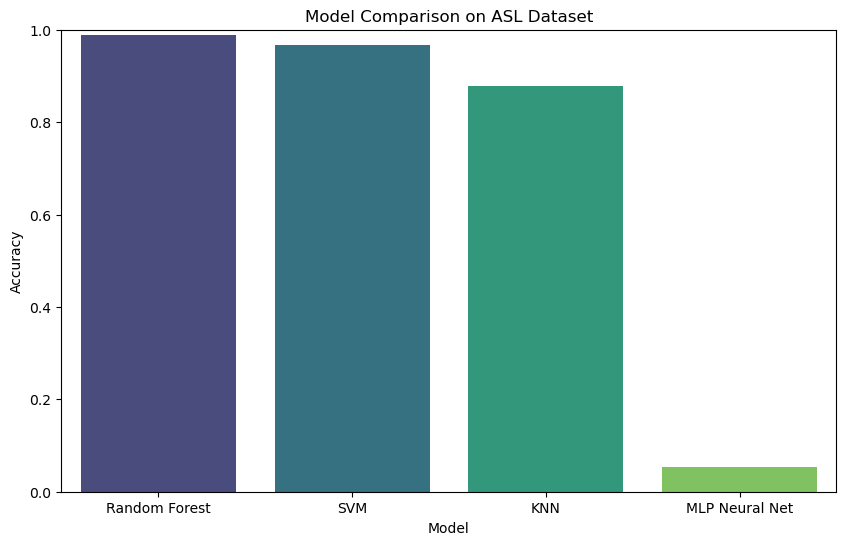

In [ ]:
# Create a DataFrame for comparison
results_df = pd.DataFrame(list(model_results.items()), columns=['Model', 'Accuracy'])
results_df['Accuracy (%)'] = results_df['Accuracy'] * 100
results_df = results_df.sort_values(by='Accuracy', ascending=False)

# Display table
print(results_df[['Model', 'Accuracy (%)']])

# Plot comparison
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')
plt.title('Model Comparison on ASL Dataset')
plt.ylim(0, 1.0)
plt.ylabel('Accuracy')
plt.show()

Test Accuracy: 87.92%

Classification Report:
              precision    recall  f1-score   support

           a       0.82      0.73      0.78        64
           b       0.89      0.94      0.92        72
           c       0.88      0.92      0.90        48
           d       0.82      0.89      0.85        65
           e       0.77      0.85      0.81        62
           f       0.96      0.78      0.86        69
           g       0.75      0.91      0.82        46
           h       0.92      0.74      0.82        61
           i       0.88      0.80      0.84        64
           k       0.83      0.88      0.85        57
           l       1.00      0.85      0.92        54
           m       0.81      0.89      0.85        56
           n       0.84      0.84      0.84        69
           o       0.90      0.98      0.94        53
           p       0.92      0.86      0.89        57
           q       1.00      1.00      1.00        65
           r       0.84      0.87  

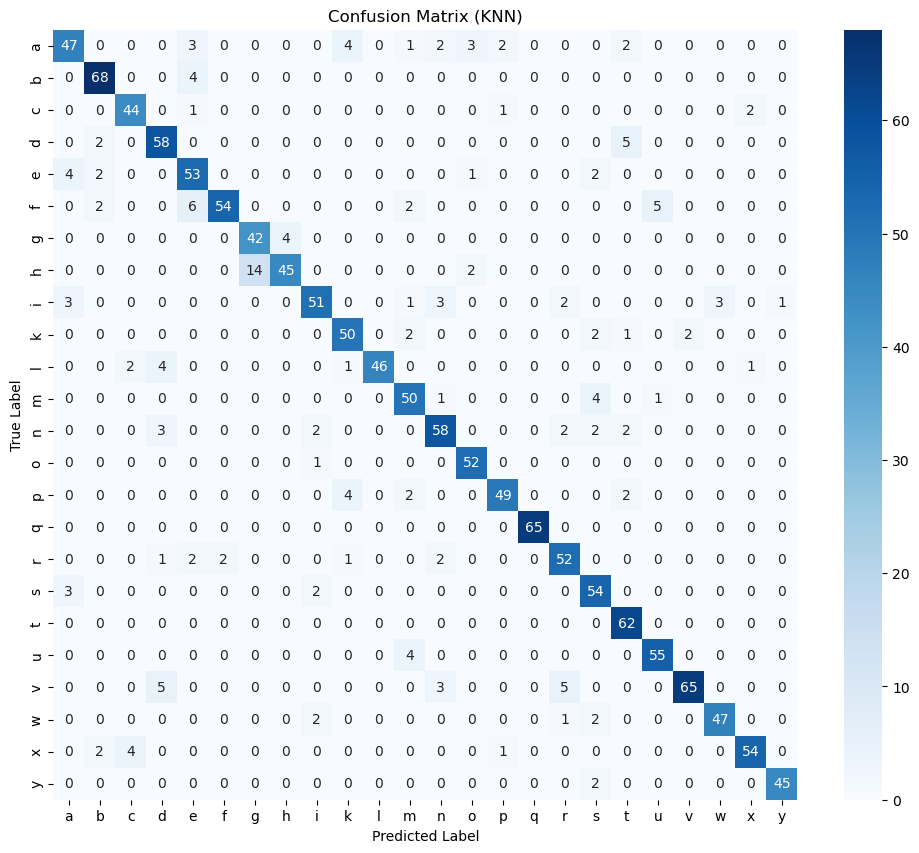

In [ ]:
# Predict on test set
# knn is used here, but we should probably use the best performing model or one specific model
# Recalculate predictions using KNN (closest to previous context)
y_pred_knn = knn.predict(X_test)

# Calculate Accuracy
acc = accuracy_score(y_test, y_pred_knn)
print(f"Test Accuracy: {acc*100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)
unique_labels = sorted(list(set(y_test)))

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=unique_labels, yticklabels=unique_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (KNN)')
plt.show()

In [ ]:
import shap

# SHAP works best with Random Forest (TreeExplainer) or generic KernelExplainer.
# We will use the trained Random Forest model 'rf' for SHAP analysis.

# Select a small background dataset for SHAP (using large datasets is slow)
# We take 20 samples from X_train
background = X_train[:20]
test_samples = X_test[:5] # Explain first 5 test samples

# Initialize TreeExplainer (optimized for Trees)
print("Initializing SHAP TreeExplainer...")
explainer = shap.TreeExplainer(rf)

# Calculate Shap Values
# check_additivity=False to avoid potential numerical precision errors validation in SHAP
shap_values = explainer.shap_values(test_samples, check_additivity=False)
print("SHAP values calculated.")

Initializing SHAP TreeExplainer...
SHAP values calculated.


Predicted Class: l (Index 10)
Plotting for class index: 10


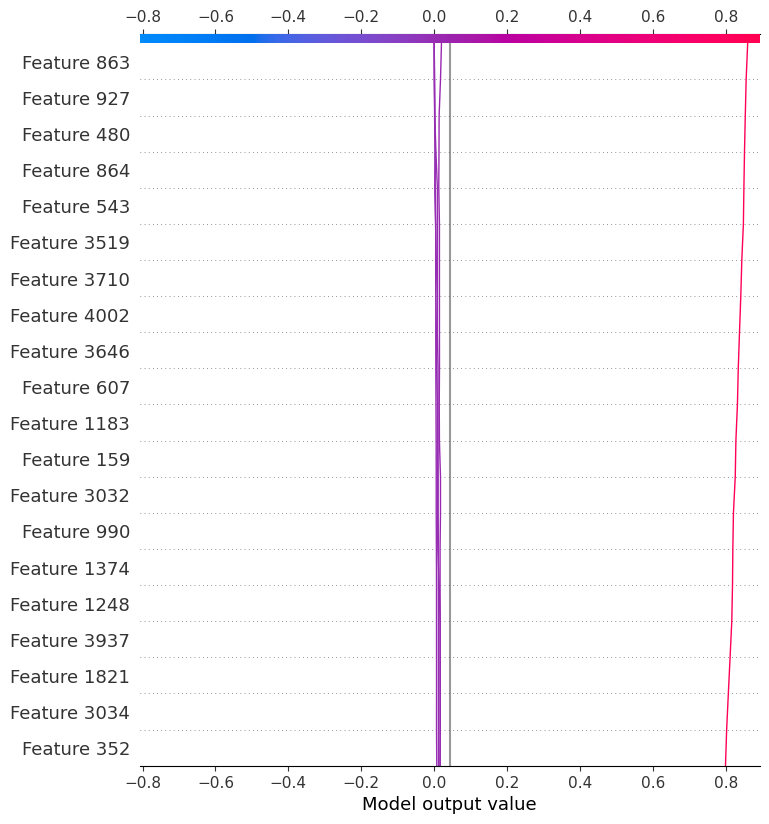

In [ ]:
# SHAP Decision Plot
shap.initjs()

# Helper to get class index
predicted_class_idx = rf.predict(test_samples[0].reshape(1, -1))[0]
class_names = rf.classes_
class_idx = np.where(class_names == predicted_class_idx)[0][0]

print(f"Predicted Class: {predicted_class_idx} (Index {class_idx})")

# Handle SHAP values structure
# It can be a list (old SHAP) or a 3D array (samples, features, classes)
shap_vals_class = None
expected_val = None

if isinstance(shap_values, list):
    # List of arrays [class_0, class_1, ...]
    shap_vals_class = shap_values[class_idx]
    if isinstance(explainer.expected_value, list) or (isinstance(explainer.expected_value, np.ndarray) and len(explainer.expected_value) == len(class_names)):
         expected_val = explainer.expected_value[class_idx]
    else:
         expected_val = explainer.expected_value
elif len(shap_values.shape) == 3:
    # Array (samples, features, classes)
    shap_vals_class = shap_values[:, :, class_idx]
    if isinstance(explainer.expected_value, np.ndarray) and len(explainer.expected_value) == len(class_names):
        expected_val = explainer.expected_value[class_idx]
    else:
        expected_val = explainer.expected_value

print(f"Plotting for class index: {class_idx}")
try:
    shap.decision_plot(expected_val, shap_vals_class, test_samples)
except Exception as e:
    print(f"Could not generate decision plot: {e}")

Force plot for class 'l':


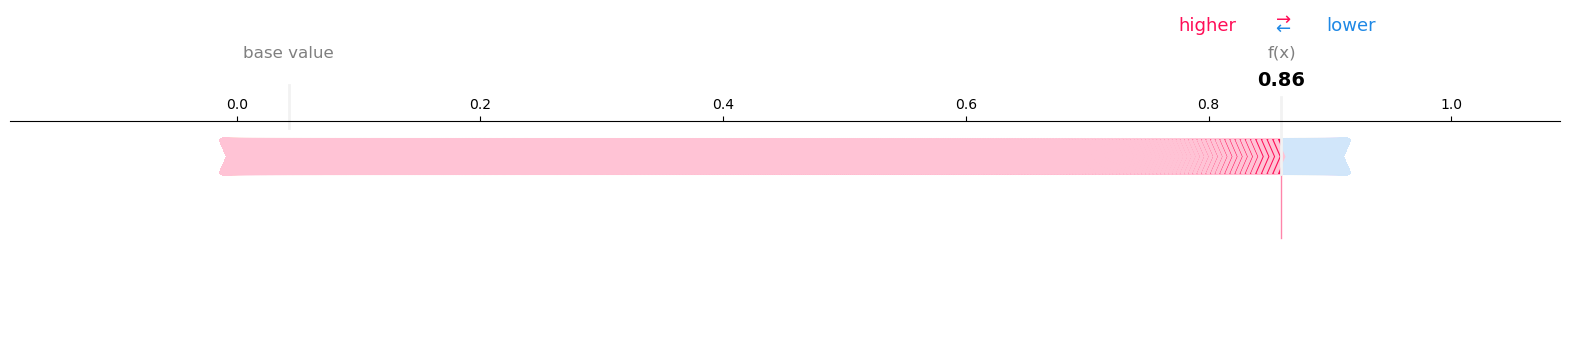

In [ ]:
# SHAP Force Plot
shap.initjs()

# Prepare values for force plot (single sample)
sample_idx = 0
if isinstance(shap_values, list):
    # Old format: list of arrays
    shap_val_sample = shap_values[class_idx][sample_idx]
elif len(shap_values.shape) == 3:
    # New format: (samples, features, classes)
    shap_val_sample = shap_values[sample_idx, :, class_idx]

print(f"Force plot for class '{class_names[class_idx]}':")
try:
    shap.force_plot(expected_val, shap_val_sample, test_samples[sample_idx], matplotlib=True)
except Exception as e:
    print(f"Could not generate force plot: {e}")